# Task 1 b
## Implementing MC with brownian motion for Backward Convection diffusion equation one high dimension


The backward heat equation in arbitrary dimensional space with terminal condition $g(x)$ reads
\begin{equation}
    \partial_t u + b \partial_x u + \sigma^2\partial_{xx}u = 0,  u(T, x) = g(x) = e^{-x^2}
\end{equation}
and has the analytical solution
\begin{equation}
    u(t, x) = \frac{1}{\sqrt{5-4t}}\exp\left( \frac{(1-t + x)^2}{5-4t} \right)
\end{equation}
where $d$ denotes dimension and $T$ is the maturity time

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Analytical solution

In [85]:
def cdexact(t, x, T):
    x = np.atleast_1d(x)
    d = x.shape[-1]
    s = 1 + 4*(T - t)
    return s**(-d/2) * np.exp(-np.sum((x + (T - t))**2, axis=-1) / s)


The equation can be written as an SDE and $X_s$ can be written as a stochastic process
\begin{equation}
    dX_s = dt +  \sqrt{2}dW_s
\end{equation}
as the PDE has $\mu = 1$ and $\sigma = \sqrt{2}$, which simplifies the general formulation $dX_s = \mu(X_s, s)dt + \sigma(X_s, s)dW_t$

Thus, the the PDE can be approximated by

\begin{equation}
    u(t,x) = \mathbb{E}[g(X_T) | X_t = x]
\end{equation}
The spatial variable can be integrated as
\begin{equation}
    X_{t + 1} = X_t + \Delta t + \sqrt{2}\Delta W_t
\end{equation}

This comes from the integration of the previous equation. Now, $W_{T-t} \sim N(0, T-t)$

The solution can then be attained with MC:
\begin{equation}
     \frac{1}{N}\sum_{i = 1}^N g(X_T) = \frac{1}{N}\sum_{i = 1}^N \exp(-(X^{(i)}_{T})^2)
\end{equation}
Where $W^{(i)}_{t} \sim N(0, 1)$ i.i.d.

Here the equation can also be solved with Euler Marauyama.

In [86]:
def W(dt, N, d):
    return np.sqrt(2*dt)*np.random.randn(N, d)

def g(x):
    return np.exp(-np.sum(x**2, axis=-1))


In [87]:
def u_MC(x, t, T, M, N, psi):
    x = np.atleast_1d(x)
    d = len(x)
    dt = (T-t) / M
    X = np.tile(x, (N, 1))
    for _ in range(M):
        X += dt + W(dt, N, d)
    vals = psi(X)
    return vals.mean(), vals.std() / np.sqrt(N)

The results can be tested and visualized (in 1 and 2 d)

In [88]:
def plot1d(x, sol, exact):
    plt.plot(x, exact, label = "Exact solution")
    plt.plot(x, sol, label = 'MC solution')
    plt.title("Exact and simulated solutions to the 1D BHE")
    plt.legend()
    plt.show()
    

In [89]:
def plot2d(sol, x1, x2, sim: bool, ax, vmin=None, vmax=None):
    lab = "MC simulated solution" if sim else "Exact solution"
    sns.heatmap(sol, cmap='coolwarm', vmin=vmin, vmax=vmax, ax=ax,
                xticklabels=np.round(x1, 2), yticklabels=np.round(x2, 2),
                cbar_kws={"label": "$u(0, x)$"})
    ax.invert_yaxis()
    ax.set_xticks(ax.get_xticks()[::5]); ax.set_yticks(ax.get_yticks()[::5])
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(lab)


First, the 1D case with only one value of $x$

In [ ]:
M = 1
N = 1000
x = 1.0
t = 0.0
T = 1.0
sol = u_MC(x, t, T, M, N, psi = g)
exact = cdexact(t, x, T)
print(f"Simulated Solution: {sol[0]}")
print(f"Exact Solution {exact}")


Simulated Solution: 0.20150303936792546
Exact Solution 0.20094602160513422


Now simulate a whole path for $x \in [x_{min}, x_{max}]$ in 1D

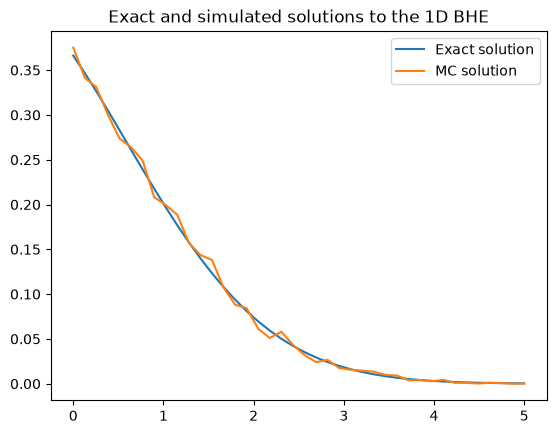

In [ ]:
M = 1
N = 1000
x_min = 0.0
x_max = 5.0
x_space = np.linspace(x_min, x_max, 40)

sol_path = np.zeros_like(x_space)
exact_path = np.array([cdexact(t, x, T) for x in x_space])

for i, x in enumerate(x_space):
    sol_path[i] = u_MC(x, t, T, M, N, psi=g)[0]

plot1d(x_space, sol=sol_path, exact = exact_path)

Evaluate the function on a 2D grid also

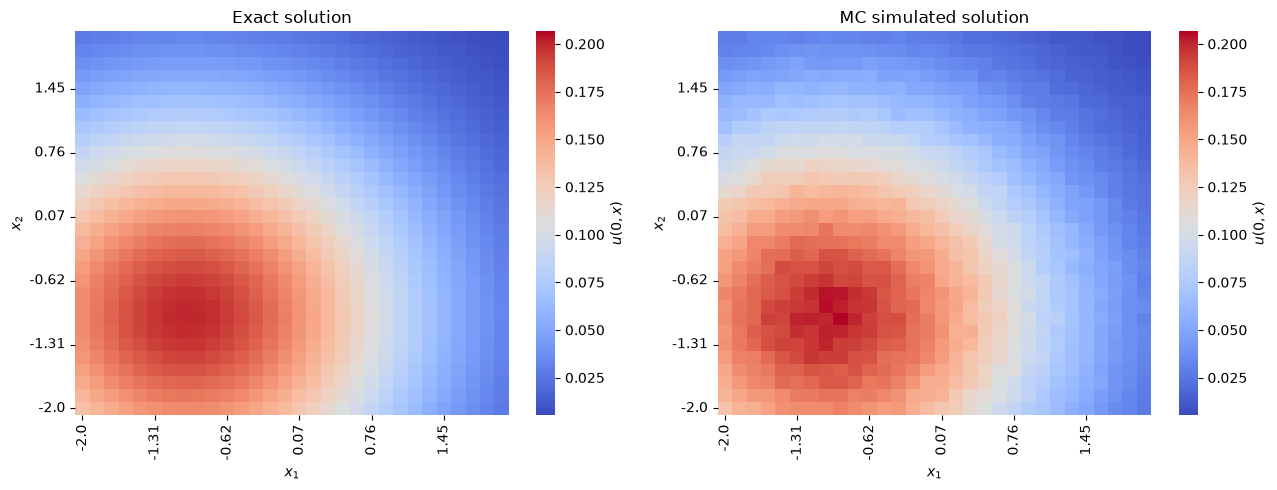

In [100]:
M = 1
N = 10000
x_min = -2.0
x_max = 2.0

x1 = np.linspace(x_min, x_max, 30) 
x2 = np.linspace(x_min, x_max, 30) 

X1, X2 = np.meshgrid(x1, x2)
points = np.stack([X1.ravel(), X2.ravel()], axis=-1)

sol_grid = np.array([u_MC(p, t, T, M, N, psi=g)[0] for p in points]).reshape(X1.shape)
exact_grid = cdexact(t, points, T).reshape(X1.shape)

vmin = min(sol_grid.min(), exact_grid.min())
vmax = max(sol_grid.max(), exact_grid.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))   # 1 row, 2 columns
plot2d(exact_grid, x1, x2, sim=False, ax=axes[0], vmin=vmin, vmax=vmax)
plot2d(sol_grid,  x1, x2, sim=True,  ax=axes[1], vmin=vmin, vmax=vmax)
plt.tight_layout()
plt.show()


In [101]:
def plot3d(sol, X1, X2, sim: bool, ax, vmin=None, vmax=None):
    lab = "MC simulated solution" if sim else "Exact solution"
    surf = ax.plot_surface(X1, X2, sol, cmap='coolwarm', vmin=vmin, vmax=vmax,
                           edgecolor='none')
    ax.set_zlim(vmin, vmax)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$u(0, x)$")
    ax.set_title(lab)
    ax.view_init(elev=30, azim=-60)
    return surf


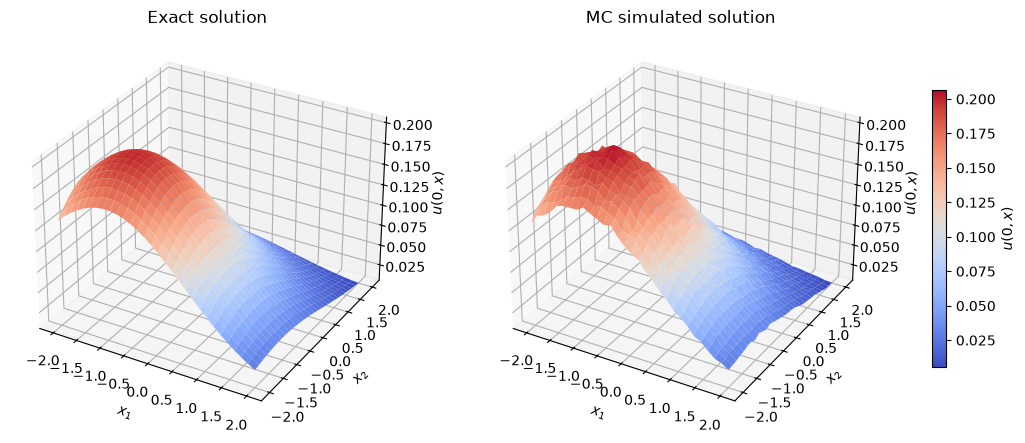

In [105]:
fig = plt.figure(figsize=(14, 6))
ax_exact = fig.add_subplot(1, 2, 1, projection='3d')
ax_mc = fig.add_subplot(1, 2, 2, projection='3d')
plot3d(exact_grid, X1, X2, sim=False, ax=ax_exact, vmin=vmin, vmax=vmax)
surf = plot3d(sol_grid, X1, X2, sim=True, ax=ax_mc, vmin=vmin, vmax=vmax)
fig.colorbar(surf, ax=[ax_exact, ax_mc], shrink=0.6, label="$u(0, x)$")
plt.show()
